In [1]:
import sys
print(sys.version)

3.11.16 (main, Aug 12 2026, 23:03:19) [Clang 21.0.0 (clang-2100.1.1.101)]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import sklearn

print("All libraries imported successfully!")
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!
TensorFlow: 2.13.1
NumPy: 1.24.3
Pandas: 2.3.3
Scikit-learn: 1.9.1


In [3]:
import pandas as pd

file_path = "../data/raw/motor_cooling_data.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (109, 11)


,Unnamed: 0,Input,Unnamed: 2,Unnamed: 3,Unnamed: 4,Output,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,Trial No.,Coolant Flow Rate (LPH),Nanoparticle Concentration (%),Motor Speed (rpm),Motor Load (%),Winding Temperature (°C),Motor Efficiency (%),Cooling Efficiency (%),Casing Temp (°C),Pumping Power (W),NaN
1,1,20,0.1,750,25,95.5,87.1,45.5,83.5,12.9,Training Data
2,2,20,0.1,750,50,100,85.8,43.5,88,12.9,NaN
3,3,20,0.1,750,75,104.5,84.6,41.5,92.5,12.9,NaN
4,4,20,0.1,750,100,109,83.3,39.5,97,12.9,NaN


In [6]:
import pandas as pd

# Load the dataset
file_path = "../data/raw/motor_cooling_data.xlsx"

df = pd.read_excel(file_path, header=1)

# Display column names
print("Column names:")
print(df.columns.tolist())

# Display dataset shape
print("\nDataset shape:", df.shape)

# Display first five rows
display(df.head())

Column names:
['Trial No.', 'Coolant Flow Rate (LPH)', 'Nanoparticle Concentration (%)', 'Motor Speed (rpm)', 'Motor Load (%)', 'Winding Temperature (°C)', 'Motor Efficiency (%)', 'Cooling Efficiency (%)', 'Casing Temp (°C)', 'Pumping Power (W)', 'Unnamed: 10']

Dataset shape: (108, 11)


,Trial No.,Coolant Flow Rate (LPH),Nanoparticle Concentration (%),Motor Speed (rpm),Motor Load (%),Winding Temperature (°C),Motor Efficiency (%),Cooling Efficiency (%),Casing Temp (°C),Pumping Power (W),Unnamed: 10
0,1,20,0.1,750,25,95.5,87.1,45.5,83.5,12.9,Training Data
1,2,20,0.1,750,50,100.0,85.8,43.5,88.0,12.9,NaN
2,3,20,0.1,750,75,104.5,84.6,41.5,92.5,12.9,NaN
3,4,20,0.1,750,100,109.0,83.3,39.5,97.0,12.9,NaN
4,5,20,0.1,1000,25,98.5,88.1,45.5,86.5,12.9,NaN


In [7]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Trial No.                       108 non-null    int64  
 1   Coolant Flow Rate (LPH)         108 non-null    int64  
 2   Nanoparticle Concentration (%)  108 non-null    float64
 3   Motor Speed (rpm)               108 non-null    int64  
 4   Motor Load (%)                  108 non-null    int64  
 5   Winding Temperature (°C)        108 non-null    float64
 6   Motor Efficiency (%)            108 non-null    float64
 7   Cooling Efficiency (%)          108 non-null    float64
 8   Casing Temp (°C)                108 non-null    float64
 9   Pumping Power (W)               108 non-null    float64
 10  Unnamed: 10                     2 non-null      object 
dtypes: float64(6), int64(4), object(1)
memory usage: 9.4+ KB

Column Names:
['Tr

,Trial No.,Coolant Flow Rate (LPH),Nanoparticle Concentration (%),Motor Speed (rpm),Motor Load (%),Winding Temperature (°C),Motor Efficiency (%),Cooling Efficiency (%),Casing Temp (°C),Pumping Power (W)
count,108.00000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000
mean,54.50000,30.000000,0.133333,1000.000000,62.500000,93.750000,88.600000,51.666667,81.750000,16.333333
std,31.32092,8.203031,0.047360,205.075778,28.081157,9.816898,2.217475,6.156829,9.816898,2.139613
min,1.00000,20.000000,0.100000,750.000000,25.000000,70.500000,83.300000,39.500000,58.500000,12.900000
25%,27.75000,20.000000,0.100000,750.000000,43.750000,86.875000,87.000000,47.375000,74.875000,14.700000
50%,54.50000,30.000000,0.100000,1000.000000,62.500000,94.250000,88.550000,51.750000,82.250000,16.500000
75%,81.25000,40.000000,0.200000,1250.000000,81.250000,101.125000,90.200000,56.000000,89.125000,17.700000
max,108.00000,40.000000,0.200000,1250.000000,100.000000,115.000000,94.200000,65.000000,103.000000,20.200000


In [8]:
# Find unnamed columns
unnamed_cols = [
    col for col in df.columns
    if str(col).startswith("Unnamed")
]

print("Unnamed columns:", unnamed_cols)

# Remove completely empty columns
df = df.dropna(axis=1, how="all")

print("Dataset shape after removing empty columns:", df.shape)
print("Remaining columns:", df.columns.tolist())

Unnamed columns: ['Unnamed: 10']
Dataset shape after removing empty columns: (108, 11)
Remaining columns: ['Trial No.', 'Coolant Flow Rate (LPH)', 'Nanoparticle Concentration (%)', 'Motor Speed (rpm)', 'Motor Load (%)', 'Winding Temperature (°C)', 'Motor Efficiency (%)', 'Cooling Efficiency (%)', 'Casing Temp (°C)', 'Pumping Power (W)', 'Unnamed: 10']


In [9]:
# Check the unnamed column
print(df["Unnamed: 10"].isnull().sum())
print(df["Unnamed: 10"].notnull().sum())

display(df["Unnamed: 10"].head(10))

106
2


0    Training Data
1              NaN
2              NaN
3              NaN
4              NaN
5              NaN
6              NaN
7              NaN
8              NaN
9              NaN
Name: Unnamed: 10, dtype: object

In [10]:
# Remove completely empty columns
df = df.dropna(axis=1, how="all")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (108, 11)
Columns: ['Trial No.', 'Coolant Flow Rate (LPH)', 'Nanoparticle Concentration (%)', 'Motor Speed (rpm)', 'Motor Load (%)', 'Winding Temperature (°C)', 'Motor Efficiency (%)', 'Cooling Efficiency (%)', 'Casing Temp (°C)', 'Pumping Power (W)', 'Unnamed: 10']


In [11]:
# Display dataset information
df.info()

# Check missing values
print(df.isnull().sum())

# Display first five rows
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Trial No.                       108 non-null    int64  
 1   Coolant Flow Rate (LPH)         108 non-null    int64  
 2   Nanoparticle Concentration (%)  108 non-null    float64
 3   Motor Speed (rpm)               108 non-null    int64  
 4   Motor Load (%)                  108 non-null    int64  
 5   Winding Temperature (°C)        108 non-null    float64
 6   Motor Efficiency (%)            108 non-null    float64
 7   Cooling Efficiency (%)          108 non-null    float64
 8   Casing Temp (°C)                108 non-null    float64
 9   Pumping Power (W)               108 non-null    float64
 10  Unnamed: 10                     2 non-null      object 
dtypes: float64(6), int64(4), object(1)
memory usage: 9.4+ KB
Trial No.                           0
Co

,Trial No.,Coolant Flow Rate (LPH),Nanoparticle Concentration (%),Motor Speed (rpm),Motor Load (%),Winding Temperature (°C),Motor Efficiency (%),Cooling Efficiency (%),Casing Temp (°C),Pumping Power (W),Unnamed: 10
0,1,20,0.1,750,25,95.5,87.1,45.5,83.5,12.9,Training Data
1,2,20,0.1,750,50,100.0,85.8,43.5,88.0,12.9,NaN
2,3,20,0.1,750,75,104.5,84.6,41.5,92.5,12.9,NaN
3,4,20,0.1,750,100,109.0,83.3,39.5,97.0,12.9,NaN
4,5,20,0.1,1000,25,98.5,88.1,45.5,86.5,12.9,NaN


In [12]:
# Check unique values in the unnamed column
print(df["Unnamed: 10"].value_counts(dropna=False))

Unnamed: 10
NaN              106
Training Data      1
Testing data       1
Name: count, dtype: int64


In [13]:
# Display rows where the column is not empty
display(df[df["Unnamed: 10"].notna()])

,Trial No.,Coolant Flow Rate (LPH),Nanoparticle Concentration (%),Motor Speed (rpm),Motor Load (%),Winding Temperature (°C),Motor Efficiency (%),Cooling Efficiency (%),Casing Temp (°C),Pumping Power (W),Unnamed: 10
0,1,20,0.1,750,25,95.5,87.1,45.5,83.5,12.9,Training Data
55,56,30,0.1,1000,100,102.5,86.4,47.5,90.5,15.9,Testing data


In [14]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (108, 11)

Column names:
['Trial No.', 'Coolant Flow Rate (LPH)', 'Nanoparticle Concentration (%)', 'Motor Speed (rpm)', 'Motor Load (%)', 'Winding Temperature (°C)', 'Motor Efficiency (%)', 'Cooling Efficiency (%)', 'Casing Temp (°C)', 'Pumping Power (W)', 'Unnamed: 10']


In [15]:
# Find rows containing training and testing labels
display(df[df["Unnamed: 10"].notna()])

,Trial No.,Coolant Flow Rate (LPH),Nanoparticle Concentration (%),Motor Speed (rpm),Motor Load (%),Winding Temperature (°C),Motor Efficiency (%),Cooling Efficiency (%),Casing Temp (°C),Pumping Power (W),Unnamed: 10
0,1,20,0.1,750,25,95.5,87.1,45.5,83.5,12.9,Training Data
55,56,30,0.1,1000,100,102.5,86.4,47.5,90.5,15.9,Testing data


In [16]:
df = df.drop(columns=["Unnamed: 10"])

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (108, 10)
Columns: ['Trial No.', 'Coolant Flow Rate (LPH)', 'Nanoparticle Concentration (%)', 'Motor Speed (rpm)', 'Motor Load (%)', 'Winding Temperature (°C)', 'Motor Efficiency (%)', 'Cooling Efficiency (%)', 'Casing Temp (°C)', 'Pumping Power (W)']


In [17]:
print(df.isnull().sum())

Trial No.                         0
Coolant Flow Rate (LPH)           0
Nanoparticle Concentration (%)    0
Motor Speed (rpm)                 0
Motor Load (%)                    0
Winding Temperature (°C)          0
Motor Efficiency (%)              0
Cooling Efficiency (%)            0
Casing Temp (°C)                  0
Pumping Power (W)                 0
dtype: int64


In [18]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [19]:
df.to_csv("../data/processed/motor_cooling_cleaned.csv",
          index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [20]:
import pandas as pd

df = pd.read_csv("../data/processed/motor_cooling_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (108, 10)


,Trial No.,Coolant Flow Rate (LPH),Nanoparticle Concentration (%),Motor Speed (rpm),Motor Load (%),Winding Temperature (°C),Motor Efficiency (%),Cooling Efficiency (%),Casing Temp (°C),Pumping Power (W)
0,1,20,0.1,750,25,95.5,87.1,45.5,83.5,12.9
1,2,20,0.1,750,50,100.0,85.8,43.5,88.0,12.9
2,3,20,0.1,750,75,104.5,84.6,41.5,92.5,12.9
3,4,20,0.1,750,100,109.0,83.3,39.5,97.0,12.9
4,5,20,0.1,1000,25,98.5,88.1,45.5,86.5,12.9


In [21]:
display(df.describe())

,Trial No.,Coolant Flow Rate (LPH),Nanoparticle Concentration (%),Motor Speed (rpm),Motor Load (%),Winding Temperature (°C),Motor Efficiency (%),Cooling Efficiency (%),Casing Temp (°C),Pumping Power (W)
count,108.00000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000
mean,54.50000,30.000000,0.133333,1000.000000,62.500000,93.750000,88.600000,51.666667,81.750000,16.333333
std,31.32092,8.203031,0.047360,205.075778,28.081157,9.816898,2.217475,6.156829,9.816898,2.139613
min,1.00000,20.000000,0.100000,750.000000,25.000000,70.500000,83.300000,39.500000,58.500000,12.900000
25%,27.75000,20.000000,0.100000,750.000000,43.750000,86.875000,87.000000,47.375000,74.875000,14.700000
50%,54.50000,30.000000,0.100000,1000.000000,62.500000,94.250000,88.550000,51.750000,82.250000,16.500000
75%,81.25000,40.000000,0.200000,1250.000000,81.250000,101.125000,90.200000,56.000000,89.125000,17.700000
max,108.00000,40.000000,0.200000,1250.000000,100.000000,115.000000,94.200000,65.000000,103.000000,20.200000


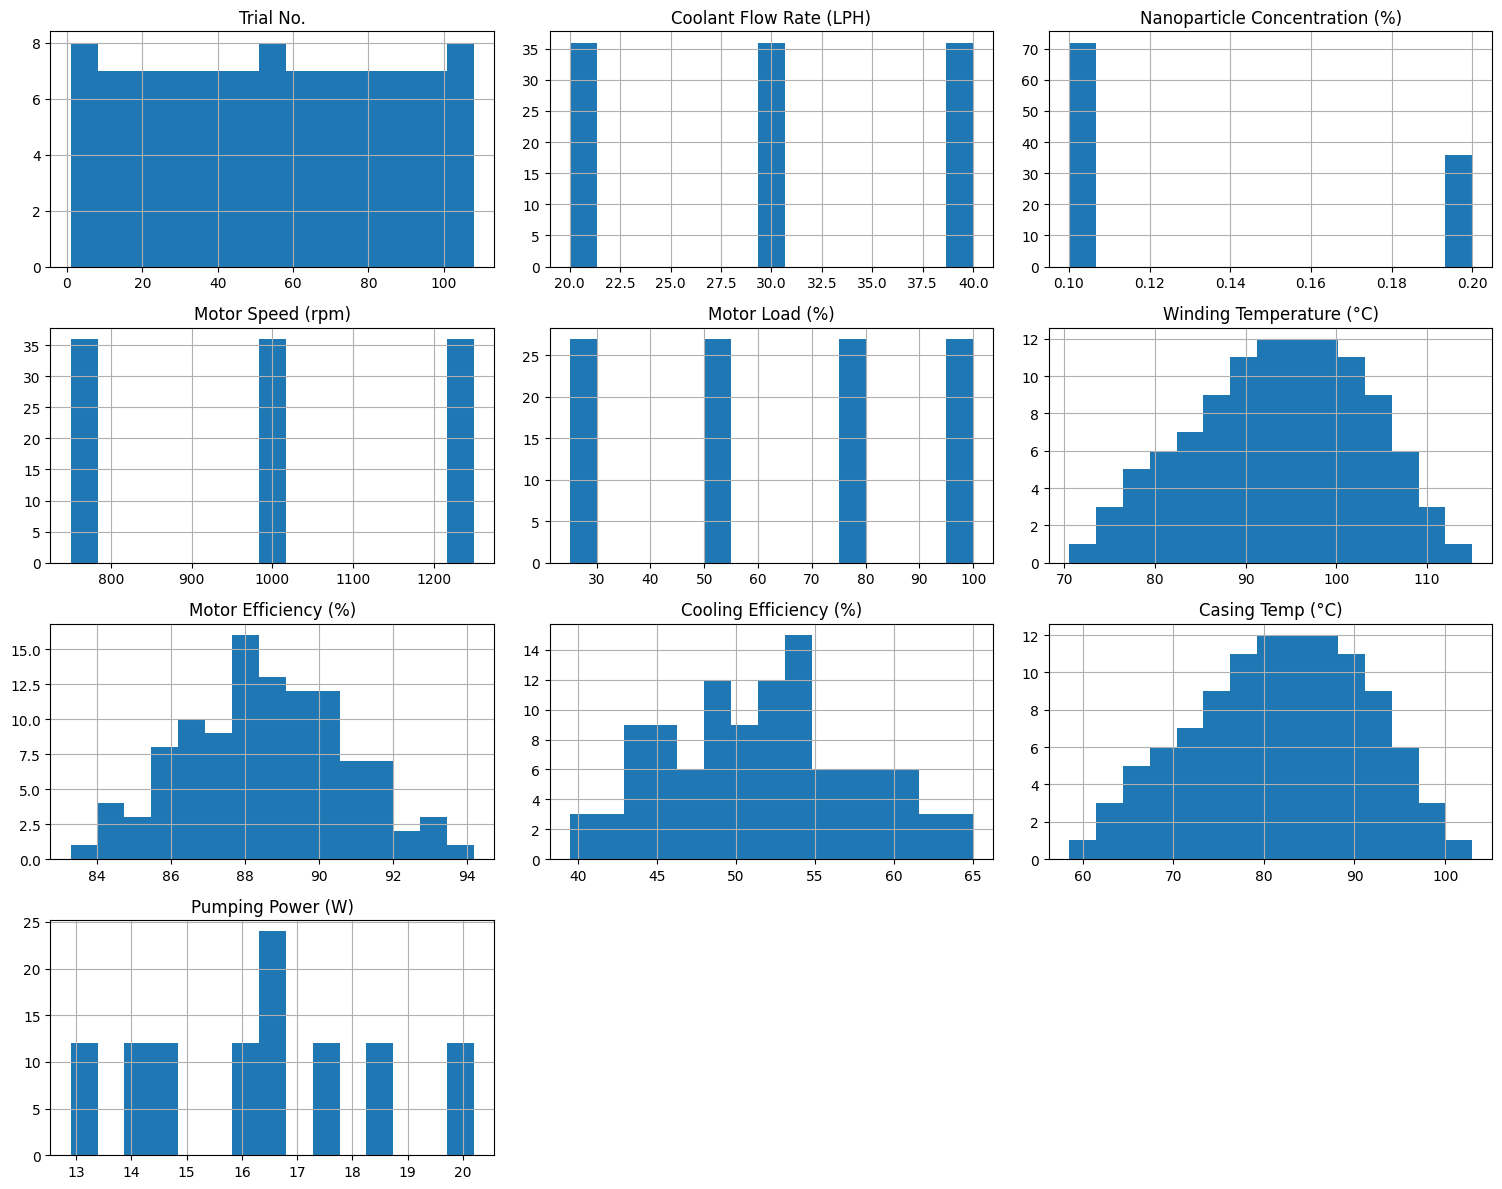

In [22]:
import matplotlib.pyplot as plt

df.hist(figsize=(15, 12), bins=15)
plt.tight_layout()
plt.show()

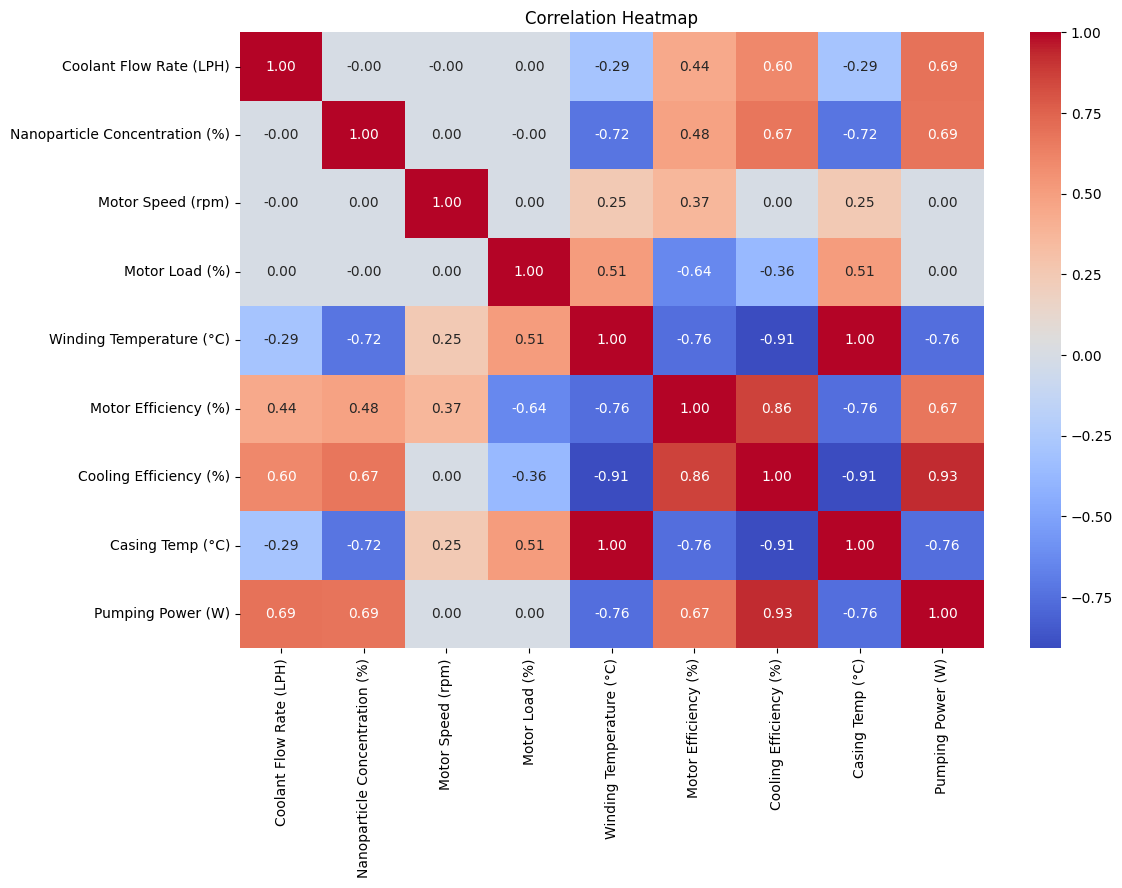

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.drop(columns=["Trial No."]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [24]:
# Define input features
input_features = [
    "Coolant Flow Rate (LPH)",
    "Nanoparticle Concentration (%)",
    "Motor Speed (rpm)",
    "Motor Load (%)"
]

# Define output parameters
output_features = [
    "Winding Temperature (°C)",
    "Motor Efficiency (%)",
    "Cooling Efficiency (%)",
    "Casing Temp (°C)",
    "Pumping Power (W)"
]

# Separate inputs and outputs
X = df[input_features]
Y = df[output_features]

print("Input shape:", X.shape)
print("Output shape:", Y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nOutput parameters:")
print(Y.columns.tolist())

Input shape: (108, 4)
Output shape: (108, 5)

Input features:
['Coolant Flow Rate (LPH)', 'Nanoparticle Concentration (%)', 'Motor Speed (rpm)', 'Motor Load (%)']

Output parameters:
['Winding Temperature (°C)', 'Motor Efficiency (%)', 'Cooling Efficiency (%)', 'Casing Temp (°C)', 'Pumping Power (W)']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
) 

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 86
Testing samples: 22
